In [ ]:
# ────────────────────────────────────────────────────────────────
# Single-cell version: Download Amharic News Dataset from Kaggle → Colab
# ────────────────────────────────────────────────────────────────

import os
import pandas as pd

# 1. Set your Kaggle API token as environment variable
os.environ['KAGGLE_API_TOKEN'] = 'KGAT_bf5339559370678651ba06ad04056c34'

# 2. Make sure kaggle cli is installed (usually already there in Colab)
!pip install -q kaggle

# 3. Download the dataset (quiet mode)
print("Downloading dataset...")
!kaggle datasets download -d mulugetalinger/news-dataset -q

# 4. Unzip it into a folder
print("Unzipping...")
!unzip -q news-dataset.zip -d amharic_news_data

# 5. (Optional) Show what files were extracted
print("\nFiles in the folder:")
!ls -lh amharic_news_data

# 6. Load the CSV — adjust filename/path if needed after seeing !ls output
DATA_PATH = "amharic_news_data/AmharicNewsDataset.csv"

try:
    data = pd.read_csv(DATA_PATH)
    print("\nDataset loaded successfully!")
    print("Shape:", data.shape)
    display(data.head(8))          # nicer output in Colab
    print("\nColumns:", list(data.columns))
except FileNotFoundError:
    print(f"\nError: Could not find {DATA_PATH}")
    print("Please check the !ls output above and adjust DATA_PATH accordingly.")
except Exception as e:
    print("\nError loading file:", str(e))

Dataset URL: https://www.kaggle.com/datasets/mulugetalinger/news-dataset
License(s): unknown
Unzipping...

Files in the folder:
total 183M
-rw-r--r-- 1 root root 183M Feb 17 13:28 AmharicNewsDataset.csv

Dataset loaded successfully!
Shape: (51483, 6)


,headline,category,date,views,article,link
0,የኦሊምፒክ ማጣሪያ ተሳታፊዎች የሚለዩበት ቻምፒዮና እየተካሄደ ይገኛል,ስፖርት,"January 14, 2021",2,ብርሃን ፈይሳየኢትዮጵያ ቦክስ ፌዴሬሽን በየዓመቱ የሚያዘጋጀው የክለቦች ቻ...,https://www.press.et/Ama/?p=39481
1,አዲስ ዘመን ድሮ,መዝናኛ,"December 28, 2020",4,የአዲስ ዘመን ጋዜጣ ቀደምት ዘገባዎች በእጅጉ ተነባቢ ዛሬም ላገኛቸው በ...,https://www.press.et/Ama/?p=38334
2,የአረንጓዴ ጎርፍ በጎ አድራጎት አምባሳደሮች ተሰየሙ,ስፖርት,"January 6, 2021",6,ቦጋለ አበበየአዲስ አበባ ከተማ አስተዳደር ስፖርት ኮሚሽን ከኢትዮጵያ አረ...,https://www.press.et/Ama/?p=39010
3,የሊጉ በቢዝነስ ሞዴል መመራት አበረታች ጅምር መሆኑ ተገለጸ,ስፖርት,"January 6, 2021",5,ብርሃን ፈይሳአዲስ አበባ፡- የኢትዮጵያ ፕሪምየር ሊግ በሼር ካምፓኒ እንዲ...,https://www.press.et/Ama/?p=39011
4,የኦሊምፒክ ሥራ አስፈፃሚው እስከ ቶኪዮ ኦሊምፒክ ማግስት ይቀጥላል,ስፖርት,"January 6, 2021",12,ቦጋለ አበበ የኢትዮጵያ ኦሊምፒክ ኮሚቴ አርባ አምስተኛ መደበኛ ጠቅላላ ጉ...,https://www.press.et/Ama/?p=39012
5,‹‹ሃገራዊ ችግሮችን ለማረምና አብሮነትን ለማጠናከር ስፖርት ወሳኝ ነው››...,ስፖርት,"December 30, 2020",10,ብርሃን ፈይሳ አዲስ አበባ፡- እንደ ሃገር እየታዩ ያሉትን ስብራቶችና ች...,https://www.press.et/Ama/?p=38512
6,በውድድር ወቅት በወረርሽኙ መከላከያ መመሪያዎች አተገባበር ላይ ስጋት እን...,ስፖርት,"December 30, 2020",3,ብርሃን ፈይሳ አዲስ አበባ፡- ስፖርታዊ እንቅስቃሴና ውድድሮች በሚከናወኑበ...,https://www.press.et/Ama/?p=38515
7,ስፖርትን ከፖለቲካ የመለየት ፈተናዎች,ስፖርት,"December 31, 2020",11,ቦጋለ አበበ‹‹ስፖርትና ፖለቲካ አንድ ናቸው ወይም ጠንካራ ግንኙነት አላቸ...,https://www.press.et/Ama/?p=38578



Columns: ['headline', 'category', 'date', 'views', 'article', 'link']


In [ ]:
# -------------------------------------------
# 1️⃣ Required Libraries
# -------------------------------------------
import re
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset

# -------------------------------------------
# 2️⃣ Load Dataset (Kaggle Path)
# -------------------------------------------
# DATA_PATH = "/content/AmharicNewsDataset.csv"

# data = pd.read_csv(DATA_PATH)

print(f"Dataset loaded: {len(data)} samples")
print("Columns:", data.columns.tolist())
print("\nOriginal class distribution:")
print(data["category"].value_counts())

# Drop unnecessary column if exists
if "Unnamed: 0" in data.columns:
    data.drop(columns=["Unnamed: 0"], inplace=True)

# Remove missing values
data = data.dropna(subset=["headline", "article", "category"]).reset_index(drop=True)
data["category"] = data["category"].astype(str)

# -------------------------------------------
# 3️⃣ Amharic Unicode + Orthographic Normalization
# -------------------------------------------
def normalize_amharic(text):
    if not isinstance(text, str):
        return text

    # Letter normalization
    replacements = [
        ('[ሃኅኃሐሓኻ]', 'ሀ'),
        ('[ሑኁዅ]', 'ሁ'),
        ('[ኂሒኺ]', 'ሂ'),
        ('[ኌሔዄ]', 'ሄ'),
        ('[ሕኅ]', 'ህ'),
        ('[ኆሖኾ]', 'ሆ'),
        ('[ሠ]', 'ሰ'),
        ('[ሡ]', 'ሱ'),
        ('[ሢ]', 'ሲ'),
        ('[ሣ]', 'ሳ'),
        ('[ሤ]', 'ሴ'),
        ('[ሥ]', 'ስ'),
        ('[ሦ]', 'ሶ'),
        ('[ዓኣዐ]', 'አ'),
        ('[ዑ]', 'ኡ'),
        ('[ዒ]', 'ኢ'),
        ('[ዔ]', 'ኤ'),
        ('[ዕ]', 'እ'),
        ('[ዖ]', 'ኦ'),
        ('[ጸ]', 'ፀ'),
        ('[ጹ]', 'ፁ'),
        ('[ጺ]', 'ፂ'),
        ('[ጻ]', 'ፃ'),
        ('[ጼ]', 'ፄ'),
        ('[ጽ]', 'ፅ'),
        ('[ጾ]', 'ፆ'),
        ('[ቊ]', 'ቁ'),
        ('[ኵ]', 'ኩ')
    ]

    for pattern, repl in replacements:
        text = re.sub(pattern, repl, text)

    # Labialized normalization
    labial_map = {
        '(ሉ[ዋአ])':'ሏ', '(ሙ[ዋአ])':'ሟ', '(ቱ[ዋአ])':'ቷ',
        '(ሩ[ዋአ])':'ሯ', '(ሱ[ዋአ])':'ሷ', '(ሹ[ዋአ])':'ሿ',
        '(ቁ[ዋአ])':'ቋ', '(ቡ[ዋአ])':'ቧ', '(ቹ[ዋአ])':'ቿ',
        '(ሁ[ዋአ])':'ኋ', '(ኑ[ዋአ])':'ኗ', '(ኙ[ዋአ])':'ኟ',
        '(ኩ[ዋአ])':'ኳ', '(ዙ[ዋአ])':'ዟ', '(ጉ[ዋአ])':'ጓ',
        '(ደ[ዋአ])':'ዷ', '(ጡ[ዋአ])':'ጧ', '(ጩ[ዋአ])':'ጯ',
        '(ጹ[ዋአ])':'ጿ', '(ፉ[ዋአ])':'ፏ'
    }

    for pattern, repl in labial_map.items():
        text = re.sub(pattern, repl, text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


print("Applying Amharic normalization...")
data["headline"] = data["headline"].apply(normalize_amharic)
data["article"]  = data["article"].apply(normalize_amharic)

# -------------------------------------------
# 4️⃣ Combine Headline + Article
# -------------------------------------------
# data["text"] = data["headline"].str.strip() + " [SEP] " + data["article"].str.strip()
data["headline"] = data["headline"].str.strip()
data["article"]  = data["article"].str.strip()

# -------------------------------------------
# 5️⃣ Remove Extremely Short Articles
# -------------------------------------------
data["word_len"] = data["article"].apply(lambda x: len(x.split()))
data = data[data["word_len"] >= 10].reset_index(drop=True)

print(f"\nDataset size after filtering: {len(data)}")
print(f"Average article length: {data['word_len'].mean():.1f} words")

# -------------------------------------------
# 6️⃣ Label Encoding
# -------------------------------------------
label_encoder = LabelEncoder()
data["label"] = label_encoder.fit_transform(data["category"])
num_labels = len(label_encoder.classes_)

print("\nNumber of classes:", num_labels)
print("Classes:", label_encoder.classes_.tolist())

print("\nClass distribution after preprocessing:")
print(data["category"].value_counts())

# -------------------------------------------
# 7️⃣ Stratified Train / Validation / Test Split
# -------------------------------------------
train_df, temp_df = train_test_split(
    data,
    test_size=0.30,
    stratify=data["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=2/3,
    stratify=temp_df["label"],
    random_state=42
)

print("\nDataset split:")
print(f"Train: {len(train_df)} ({100*len(train_df)/len(data):.1f}%)")
print(f"Val:   {len(val_df)} ({100*len(val_df)/len(data):.1f}%)")
print(f"Test:  {len(test_df)} ({100*len(test_df)/len(data):.1f}%)")

# -------------------------------------------
# 8️⃣ Convert to HuggingFace Dataset (For Transformers)
# -------------------------------------------
# train_dataset = Dataset.from_pandas(train_df[["text", "label"]])
# val_dataset   = Dataset.from_pandas(val_df[["text", "label"]])
# test_dataset  = Dataset.from_pandas(test_df[["text", "label"]])
train_dataset = Dataset.from_pandas(train_df[["headline", "article", "label"]])
val_dataset   = Dataset.from_pandas(val_df[["headline", "article", "label"]])
test_dataset  = Dataset.from_pandas(test_df[["headline", "article", "label"]])

print("\nPreprocessing COMPLETE")
print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

Dataset loaded: 51483 samples
Columns: ['headline', 'category', 'date', 'views', 'article', 'link']

Original class distribution:
category
ሀገር አቀፍ ዜና    20674
ስፖርት          10411
ፖለቲካ           9325
ዓለም አቀፍ ዜና     6543
ቢዝነስ           3894
መዝናኛ            635
Name: count, dtype: int64
Applying Amharic normalization...

Dataset size after filtering: 50871
Average article length: 251.9 words

Number of classes: 6
Classes: ['ሀገር አቀፍ ዜና', 'መዝናኛ', 'ስፖርት', 'ቢዝነስ', 'ዓለም አቀፍ ዜና', 'ፖለቲካ']

Class distribution after preprocessing:
category
ሀገር አቀፍ ዜና    20509
ስፖርት          10165
ፖለቲካ           9213
ዓለም አቀፍ ዜና     6502
ቢዝነስ           3850
መዝናኛ            632
Name: count, dtype: int64

Dataset split:
Train: 35609 (70.0%)
Val:   5087 (10.0%)
Test:  10175 (20.0%)

Preprocessing COMPLETE
Train: 35609 | Val: 5087 | Test: 10175


afriberta + focal loss

Using device: cuda


Loading weights:   0%|          | 0/165 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: castorini/afriberta_large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.decoder.weight          | UNEXPECTED | 
lm_head.decoder.bias            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/35609 [00:00<?, ? examples/s]

Map:   0%|          | 0/5087 [00:00<?, ? examples/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

Step,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
400,1.274395,0.269072,0.765677,0.618186,0.752183
800,0.838863,0.187081,0.840377,0.745782,0.839695
1200,0.595454,0.168163,0.863181,0.740485,0.859694
1600,0.526358,0.138340,0.876351,0.845346,0.878426
2000,0.509679,0.121186,0.886377,0.853408,0.886150
2400,0.382512,0.125802,0.892078,0.853391,0.890802
2800,0.390969,0.121444,0.893257,0.830158,0.892153
3200,0.369517,0.148260,0.875369,0.855516,0.875299
3600,0.273332,0.117696,0.900138,0.881401,0.901185
4000,0.269163,0.130949,0.894044,0.870905,0.894949



Evaluating on test set...



CLASSIFICATION REPORT
              precision    recall  f1-score   support

  ሀገር አቀፍ ዜና       0.92      0.88      0.90      4102
        መዝናኛ       0.86      0.86      0.86       126
        ስፖርት       0.99      0.99      0.99      2033
        ቢዝነስ       0.68      0.81      0.74       770
  ዓለም አቀፍ ዜና       0.90      0.94      0.92      1301
        ፖለቲካ       0.87      0.84      0.85      1843

    accuracy                           0.90     10175
   macro avg       0.87      0.89      0.88     10175
weighted avg       0.90      0.90      0.90     10175


SUMMARY METRICS
Accuracy:     0.8998
Macro F1:     0.8772
Weighted F1:  0.9008
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-noto is already the newest version (20201225-1build1).
0 upgraded, 0 newly installed, 0 to remove and 45 not upgraded.


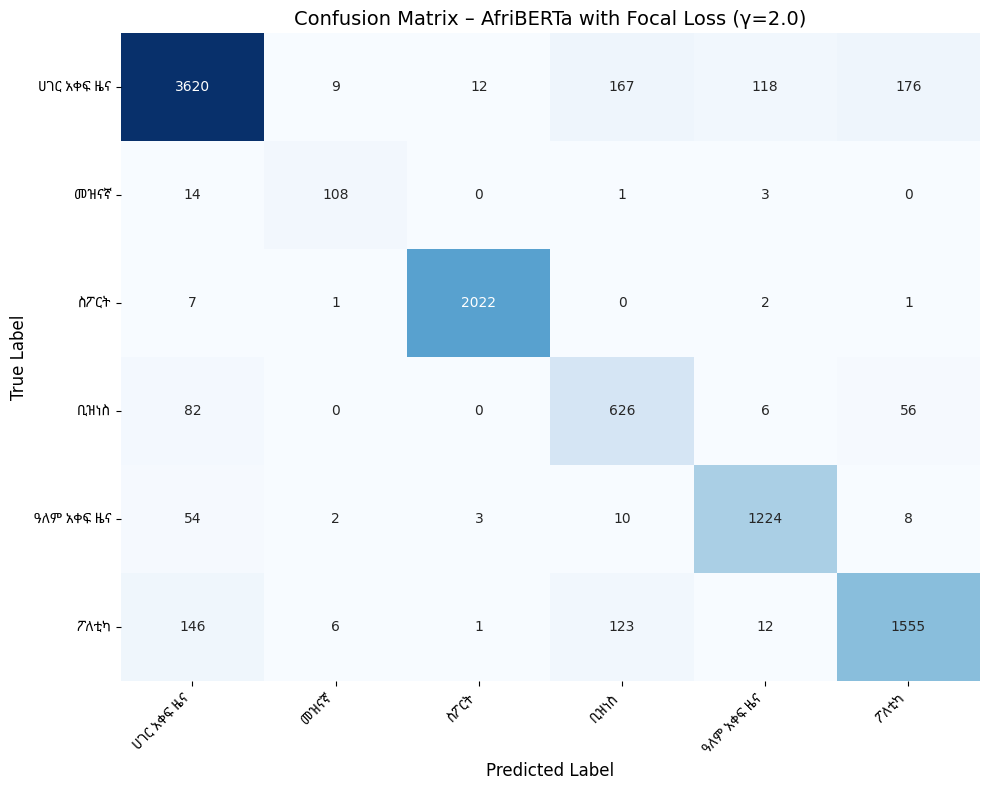


Training complete!


In [ ]:
# ==========================================================
# AfriBERTa-Large – FOCAL LOSS VERSION
# Class Imbalance Handling with Focal Loss
# ==========================================================

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager as fm

from transformers import (
    AutoTokenizer,
    AutoConfig,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# -------------------
# 0️⃣ Device
# -------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# -------------------
# 1️⃣ Load  dataset
# -------------------
# Make sure you have your datasets loaded as:
# train_dataset, val_dataset, test_dataset, label_encoder, num_labels
# Example:
# from datasets import Dataset
# train_dataset = Dataset.from_pandas(train_df)
# val_dataset = Dataset.from_pandas(val_df)
# test_dataset = Dataset.from_pandas(test_df)

# -------------------
# 2️⃣ Model & Tokenizer
# -------------------
model_name = "castorini/afriberta_large"

tokenizer = AutoTokenizer.from_pretrained(model_name)

config = AutoConfig.from_pretrained(
    model_name,
    num_labels=num_labels,
    hidden_dropout_prob=0.2,
    attention_probs_dropout_prob=0.2
)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    config=config,
    ignore_mismatched_sizes=True
).to(device)

model.config.max_length = None

# -------------------
# 3️⃣ Tokenization
# -------------------
def tokenize(batch):
    return tokenizer(
        batch["headline"],
        batch["article"],
        truncation=True,
        padding=True,
        max_length=512
    )

# train_dataset = train_dataset.rename_column("label", "labels")
# val_dataset = val_dataset.rename_column("label", "labels")
# test_dataset = test_dataset.rename_column("label", "labels")

train_dataset = train_dataset.map(tokenize, batched=True)
val_dataset = val_dataset.map(tokenize, batched=True)
test_dataset = test_dataset.map(tokenize, batched=True)

for ds in [train_dataset, val_dataset, test_dataset]:
    ds.set_format(
        type="torch",
        columns=["input_ids", "attention_mask", "labels"]
    )

# -------------------
# 4️⃣ Focal Loss Implementation
# -------------------
class FocalLossTrainer(Trainer):
    """
    Custom Trainer with Focal Loss for handling class imbalance.
    Focal Loss focuses on hard-to-classify examples by down-weighting easy examples.

    Formula: FL(p_t) = -α_t * (1 - p_t)^γ * log(p_t)
    where:
    - γ (gamma) controls the focusing strength (higher γ focuses more on hard examples)
    - α (alpha) balances class importance (similar to class weights)
    """

    def __init__(self, gamma=2.0, alpha=None, **kwargs):
        super().__init__(**kwargs)
        self.gamma = gamma
        self.alpha = alpha  # Can be class weights tensor

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        # Calculate cross-entropy loss without reduction
        ce_loss = torch.nn.CrossEntropyLoss(reduction='none')
        ce_loss_values = ce_loss(logits, labels)

        # Calculate p_t (probability of correct class)
        # p_t = exp(-CE) because CE = -log(p_t)
        pt = torch.exp(-ce_loss_values)

        # Calculate focal weight: (1 - p_t)^gamma
        focal_weight = (1 - pt) ** self.gamma

        # Apply alpha (class weights) if provided
        if self.alpha is not None:
            # Move alpha to same device as logits
            alpha_t = self.alpha[labels].to(logits.device)
            focal_weight = alpha_t * focal_weight

        # Apply focal weight to loss
        focal_loss = focal_weight * ce_loss_values

        # Return mean loss
        loss = focal_loss.mean()

        return (loss, outputs) if return_outputs else loss


# -------------------
# 5️⃣ Optional: Calculate Class Weights (if using alpha)
# -------------------
from sklearn.utils.class_weight import compute_class_weight

# Calculate class weights for alpha parameter (optional)
labels_np = np.array(train_dataset["labels"]).astype(int)
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(num_labels),
    y=labels_np
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float)
print("Class weights (for alpha):", class_weights_tensor)

# -------------------
# 6️⃣ Metrics Function
# -------------------
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro"),
        "weighted_f1": f1_score(labels, preds, average="weighted")
    }

# -------------------
# 7️⃣ Training Arguments (Optimized)
# -------------------
training_args = TrainingArguments(
    output_dir="./afriberta_large_focal_loss",

    # Batch size settings
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=4,

    # Training settings
    num_train_epochs=8,
    learning_rate=2e-5,
    lr_scheduler_type="cosine",
    warmup_ratio=0.1,
    weight_decay=0.05,

    # Evaluation and saving
    eval_strategy="steps",
    save_strategy="steps",
    eval_steps=400,
    save_steps=400,
    logging_strategy="steps",
    logging_steps=100,

    # Best model selection
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    # Optimization
    fp16=torch.cuda.is_available(),
    max_grad_norm=1.0,

    # Logging
    report_to="none"
)

# -------------------
# 8️⃣ Create Trainer with Focal Loss
# -------------------
# Choose focal loss configuration:

# Option A: Focal Loss WITHOUT class weights (just gamma)
trainer = FocalLossTrainer(
    gamma=2.0,                          # Focus on hard examples
    alpha=None,                         # No class weights
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

# Option B: Focal Loss WITH class weights
# Uncomment this version if you want to combine focal loss with class weights
"""
trainer = FocalLossTrainer(
    gamma=2.0,                          # Try 2.0, 3.0, or 5.0
    alpha=class_weights_tensor,         # Use class weights
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)
"""

# Option C: Focal Loss with custom manual weights (for more control)
# Uncomment if you want manual control over class weights
"""
custom_weights = torch.tensor([
    0.6,    # Local News
    20.0,   # Entertainment
    0.7,    # Sport
    5.0,    # Business (focus more on this)
    2.0,    # International
    1.2     # Politics
], dtype=torch.float)

trainer = FocalLossTrainer(
    gamma=2.5,                          # Slightly higher gamma
    alpha=custom_weights,               # Use custom weights
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)
"""

# -------------------
# 9️⃣ Train the Model
# -------------------
print("Starting training with Focal Loss...")
print(f"Focal Loss gamma: {trainer.gamma}")
print(f"Using alpha: {trainer.alpha is not None}")

trainer.train()

# -------------------
# 🔟 Evaluation
# -------------------
print("\nEvaluating on test set...")
preds = trainer.predict(test_dataset)

y_pred = np.argmax(preds.predictions, axis=1)
y_true = np.array(test_dataset["labels"])

# Print classification report
print("\n" + "="*60)
print("CLASSIFICATION REPORT")
print("="*60)
print(
    classification_report(
        y_true,
        y_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Calculate and display additional metrics
accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")
weighted_f1 = f1_score(y_true, y_pred, average="weighted")

print("\n" + "="*60)
print("SUMMARY METRICS")
print("="*60)
print(f"Accuracy:     {accuracy:.4f}")
print(f"Macro F1:     {macro_f1:.4f}")
print(f"Weighted F1:  {weighted_f1:.4f}")

# -------------------
# 1️⃣1️⃣ Confusion Matrix (Amharic Labels)
# -------------------
cm = confusion_matrix(y_true, y_pred)

# Install font if not already installed
!apt-get install -y fonts-noto

# Try common font paths
font_paths = [
    "/content/NotoSansEthiopic-VariableFont_wdth,wght.ttf",
    "/usr/share/fonts/truetype/noto/NotoSansEthiopic-Regular.ttf",
    "/usr/share/fonts/opentype/noto/NotoSansEthiopic-Regular.otf"
]

font_path = None
for path in font_paths:
    import os
    if os.path.exists(path):
        font_path = path
        break

if font_path:
    font_prop = fm.FontProperties(fname=font_path)
else:
    font_prop = None
    print("Warning: Amharic font not found. Using default font.")

plt.figure(figsize=(10, 8))

ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cbar=False,
    cmap="Blues"
)

# Set labels with Amharic fonts if available
if font_prop:
    ax.set_xticklabels(
        label_encoder.classes_,
        rotation=45,
        ha="right",
        fontproperties=font_prop
    )
    ax.set_yticklabels(
        label_encoder.classes_,
        rotation=0,
        fontproperties=font_prop
    )
else:
    ax.set_xticklabels(
        label_encoder.classes_,
        rotation=45,
        ha="right"
    )
    ax.set_yticklabels(
        label_encoder.classes_,
        rotation=0
    )

ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("True Label", fontsize=12)
ax.set_title(f"Confusion Matrix – AfriBERTa with Focal Loss (γ={trainer.gamma})", fontsize=14)

plt.tight_layout()
plt.show()

# -------------------
# 1️⃣2️⃣ Optional: Experiment with Different Gamma Values
# -------------------
# If you want to try multiple gamma values, uncomment this section
"""
gamma_values = [1.0, 2.0, 3.0, 5.0]
results = {}

for gamma in gamma_values:
    print(f"\n{'='*60}")
    print(f"Training with gamma = {gamma}")
    print('='*60)

    # Re-initialize model for each run
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        config=config,
        ignore_mismatched_sizes=True
    ).to(device)

    trainer = FocalLossTrainer(
        gamma=gamma,
        alpha=class_weights_tensor,
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
    )

    trainer.train()
    preds = trainer.predict(test_dataset)
    y_pred = np.argmax(preds.predictions, axis=1)

    results[gamma] = {
        'macro_f1': f1_score(y_true, y_pred, average="macro"),
        'weighted_f1': f1_score(y_true, y_pred, average="weighted"),
        'accuracy': accuracy_score(y_true, y_pred)
    }

    print(f"Gamma {gamma}: Macro F1 = {results[gamma]['macro_f1']:.4f}")

# Plot results
gammas = list(results.keys())
macro_f1s = [results[g]['macro_f1'] for g in gammas]

plt.figure(figsize=(8, 5))
plt.plot(gammas, macro_f1s, marker='o', linestyle='-', linewidth=2)
plt.xlabel('Gamma Value')
plt.ylabel('Macro F1 Score')
plt.title('Effect of Gamma on Model Performance')
plt.grid(True)
plt.show()
"""

print("\nTraining complete!")

Using device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/731 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/257 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/1.55M [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye


Evaluating on test set...



CLASSIFICATION REPORT - BASELINE (No Imbalance Handling)
              precision    recall  f1-score   support

  ሀገር አቀፍ ዜና       0.93      0.86      0.89      4102
        መዝናኛ       0.80      0.83      0.81       126
        ስፖርት       0.98      1.00      0.99      2033
        ቢዝነስ       0.67      0.80      0.73       770
  ዓለም አቀፍ ዜና       0.90      0.94      0.92      1301
        ፖለቲካ       0.84      0.86      0.85      1843

    accuracy                           0.89     10175
   macro avg       0.85      0.88      0.87     10175
weighted avg       0.90      0.89      0.90     10175


SUMMARY METRICS - BASELINE
Accuracy:     0.8946
Macro F1:     0.8667
Weighted F1:  0.8957

PER-CLASS F1 SCORES
ሀገር አቀፍ ዜና          : 0.8949
መዝናኛ                : 0.8140
ስፖርት                : 0.9922
ቢዝነስ                : 0.7319
ዓለም አቀፍ ዜና          : 0.9183
ፖለቲካ                : 0.8492
Selecting previously unselected package fonts-noto-core.
(Reading database ... 122354 files and directories curre

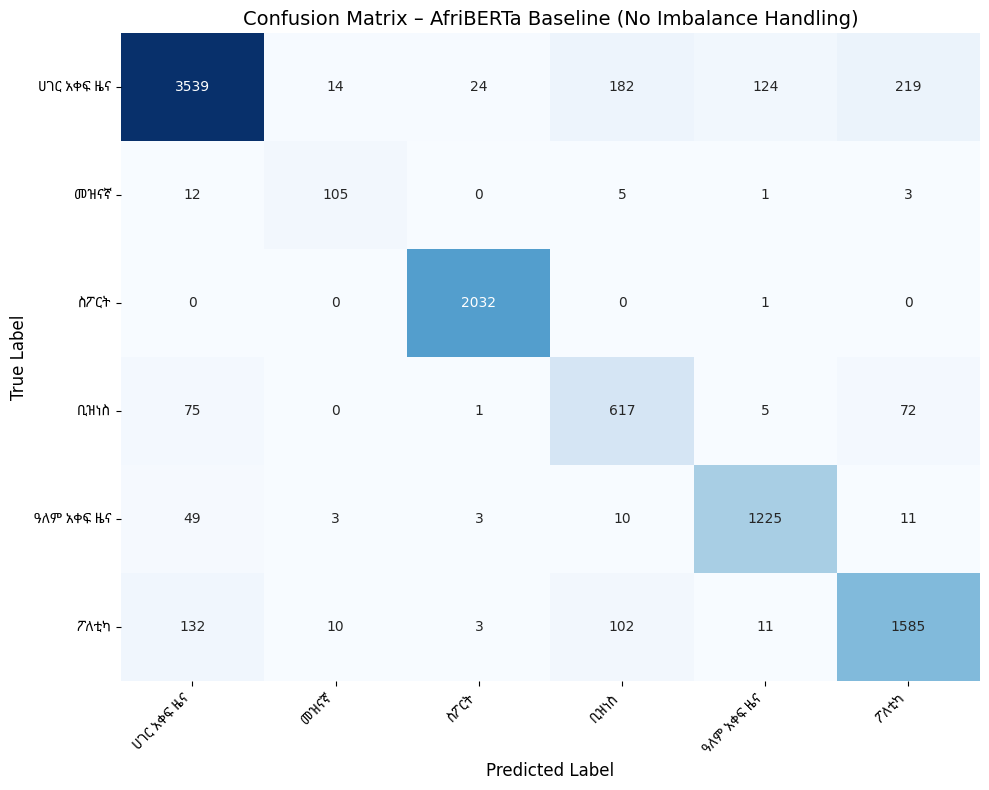


Baseline results saved to 'baseline_results.pkl'

MISCLASSIFICATION ANALYSIS
Total misclassified samples: 1072/10175 (10.54%)

Example misclassifications for BUSINESS class (total: 153):

Example 1:
Headline: ኢትዮጵያ የምግብ ዋስትና አለማቀፍ ጉባኤ እያስተናገደች ነው
True: Business
Predicted: ሀገር አቀፍ ዜና
--------------------------------------------------

Example 2:
Headline: ኢትዮጵያ የለውጥ ጉዞ ፈተናዎችን በአስተውሎት ለመሻገር እና አስተማማኝ ሰላም ለመገንባት ፅኑ አቋም አላት
True: Business
Predicted: ሀገር አቀፍ ዜና
--------------------------------------------------

Example 3:
Headline: ህገወጦችን ህጋዊ ለማድረግ ከፍተኛ የሊዝ ክፍያ ተጠየቀ
True: Business
Predicted: ሀገር አቀፍ ዜና
--------------------------------------------------

Example 4:
Headline: አመራሩና ባለሙያው የከተማ ፖሊሲና ስትራቴጅዎችን አውቆ መፈፀም እንዳለበት ተመለከተ
True: Business
Predicted: ፖለቲካ
--------------------------------------------------

Example 5:
Headline: ፓትርያርኩ ለመቄዶንያ 100 ሺህ ብር ለገሱ
True: Business
Predicted: ሀገር አቀፍ ዜና
--------------------------------------------------

Example misclassifications for ENTERTAINMENT c

In [ ]:
# ==========================================================
# AfriBERTa-Large – BASELINE (No Imbalance Handling)
# Same hyperparameters as Focal Loss experiment - FIXED VERSION
# ==========================================================

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager as fm

from transformers import (
    AutoTokenizer,
    AutoConfig,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# -------------------
# 0️⃣ Device
# -------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# -------------------
# 1️⃣ Load your dataset (Assuming you already have it loaded)
# -------------------
# Make sure you have your datasets loaded as:
# train_dataset, val_dataset, test_dataset, label_encoder, num_labels

# Store the original test dataset BEFORE tokenization for text access
original_test_dataset = test_dataset

# -------------------
# 2️⃣ Model & Tokenizer
# -------------------
model_name = "castorini/afriberta_large"

tokenizer = AutoTokenizer.from_pretrained(model_name)

config = AutoConfig.from_pretrained(
    model_name,
    num_labels=num_labels,
    hidden_dropout_prob=0.2,
    attention_probs_dropout_prob=0.2
)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    config=config,
    ignore_mismatched_sizes=True
).to(device)

model.config.max_length = None

# -------------------
# 3️⃣ Tokenization (SAME as focal loss experiment)
# -------------------
def tokenize(batch):
    return tokenizer(
        batch["headline"],
        batch["article"],
        truncation=True,
        padding=True,
        max_length=512
    )

# Rename label column to "labels" for HuggingFace compatibility
train_dataset = train_dataset.rename_column("label", "labels")
val_dataset = val_dataset.rename_column("label", "labels")
test_dataset = test_dataset.rename_column("label", "labels")

# Tokenize datasets
train_dataset = train_dataset.map(tokenize, batched=True)
val_dataset = val_dataset.map(tokenize, batched=True)
test_dataset = test_dataset.map(tokenize, batched=True)

# Format to PyTorch tensors
for ds in [train_dataset, val_dataset, test_dataset]:
    ds.set_format(
        type="torch",
        columns=["input_ids", "attention_mask", "labels"]
    )

# -------------------
# 4️⃣ Metrics Function (SAME as focal loss experiment)
# -------------------
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro"),
        "weighted_f1": f1_score(labels, preds, average="weighted")
    }

# -------------------
# 5️⃣ Training Arguments (IDENTICAL to focal loss experiment)
# -------------------
training_args = TrainingArguments(
    output_dir="./afriberta_large_baseline",

    # Batch size settings - SAME as focal loss
    per_device_train_batch_size=8,      # Same as focal loss
    per_device_eval_batch_size=16,      # Same as focal loss
    gradient_accumulation_steps=4,      # Same as focal loss (effective batch = 32)

    # Training settings - SAME as focal loss
    num_train_epochs=8,                  # Same as focal loss
    learning_rate=2e-5,                 # Same as focal loss
    lr_scheduler_type="cosine",         # Same as focal loss
    warmup_ratio=0.1,                   # Same as focal loss
    weight_decay=0.05,                  # Same as focal loss

    # Evaluation and saving - SAME as focal loss
    eval_strategy="steps",
    save_strategy="steps",
    eval_steps=400,                      # Same as focal loss
    save_steps=400,                      # Same as focal loss
    logging_strategy="steps",
    logging_steps=100,                   # Same as focal loss

    # Best model selection - SAME as focal loss
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    # Optimization - SAME as focal loss
    fp16=torch.cuda.is_available(),
    max_grad_norm=1.0,

    # Logging
    report_to="none",
    save_total_limit=2,                  # Keep only best 2 checkpoints
)

# -------------------
# 6️⃣ Standard Trainer (NO imbalance handling)
# -------------------
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]  # Same patience as focal loss
)

# -------------------
# 7️⃣ Train the Model
# -------------------
print("="*60)
print("Starting BASELINE training (No imbalance handling)...")
print("="*60)
print(f"Model: {model_name}")
print(f"Batch size (effective): {training_args.per_device_train_batch_size * training_args.gradient_accumulation_steps}")
print(f"Learning rate: {training_args.learning_rate}")
print(f"Epochs: {training_args.num_train_epochs}")
print("="*60)

trainer.train()

# -------------------
# 8️⃣ Evaluation on Test Set
# -------------------
print("\nEvaluating on test set...")
preds = trainer.predict(test_dataset)

y_pred = np.argmax(preds.predictions, axis=1)
y_true = np.array(test_dataset["labels"])

# Print classification report
print("\n" + "="*60)
print("CLASSIFICATION REPORT - BASELINE (No Imbalance Handling)")
print("="*60)
print(
    classification_report(
        y_true,
        y_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Calculate and display additional metrics
accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")
weighted_f1 = f1_score(y_true, y_pred, average="weighted")

print("\n" + "="*60)
print("SUMMARY METRICS - BASELINE")
print("="*60)
print(f"Accuracy:     {accuracy:.4f}")
print(f"Macro F1:     {macro_f1:.4f}")
print(f"Weighted F1:  {weighted_f1:.4f}")

# Per-class F1 scores for detailed comparison
per_class_f1 = f1_score(y_true, y_pred, average=None)
print("\n" + "="*60)
print("PER-CLASS F1 SCORES")
print("="*60)
for i, class_name in enumerate(label_encoder.classes_):
    print(f"{class_name:20s}: {per_class_f1[i]:.4f}")

# -------------------
# 9️⃣ Confusion Matrix
# -------------------
cm = confusion_matrix(y_true, y_pred)

# Install font if not already installed
!apt-get install -y fonts-noto -qq

# Try common font paths
font_paths = [
    "/content/NotoSansEthiopic-VariableFont_wdth,wght.ttf",
    "/usr/share/fonts/truetype/noto/NotoSansEthiopic-Regular.ttf",
    "/usr/share/fonts/opentype/noto/NotoSansEthiopic-Regular.otf"
]

font_path = None
for path in font_paths:
    import os
    if os.path.exists(path):
        font_path = path
        break

if font_path:
    font_prop = fm.FontProperties(fname=font_path)
else:
    font_prop = None
    print("Warning: Amharic font not found. Using default font.")

plt.figure(figsize=(10, 8))

ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cbar=False,
    cmap="Blues",
    annot_kws={'size': 10}
)

# Set labels with Amharic fonts if available
if font_prop:
    ax.set_xticklabels(
        label_encoder.classes_,
        rotation=45,
        ha="right",
        fontproperties=font_prop,
        fontsize=10
    )
    ax.set_yticklabels(
        label_encoder.classes_,
        rotation=0,
        fontproperties=font_prop,
        fontsize=10
    )
else:
    ax.set_xticklabels(
        label_encoder.classes_,
        rotation=45,
        ha="right",
        fontsize=10
    )
    ax.set_yticklabels(
        label_encoder.classes_,
        rotation=0,
        fontsize=10
    )

ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("True Label", fontsize=12)
ax.set_title("Confusion Matrix – AfriBERTa Baseline (No Imbalance Handling)", fontsize=14)

plt.tight_layout()
plt.show()

# -------------------
# 🔟 Save Results for Comparison
# -------------------
baseline_results = {
    'accuracy': accuracy,
    'macro_f1': macro_f1,
    'weighted_f1': weighted_f1,
    'per_class_f1': per_class_f1,
    'predictions': y_pred,
    'true_labels': y_true
}

# Save to file for later comparison
import pickle
with open('baseline_results.pkl', 'wb') as f:
    pickle.dump(baseline_results, f)

print("\nBaseline results saved to 'baseline_results.pkl'")

# -------------------
# 1️⃣1️⃣ Quick Analysis of Misclassifications (FIXED VERSION)
# -------------------
print("\n" + "="*60)
print("MISCLASSIFICATION ANALYSIS")
print("="*60)

# Find misclassified indices
misclassified_idx = np.where(y_pred != y_true)[0]
print(f"Total misclassified samples: {len(misclassified_idx)}/{len(y_true)} ({len(misclassified_idx)/len(y_true)*100:.2f}%)")

# Create mapping from class names to indices
class_to_idx = {name: idx for idx, name in enumerate(label_encoder.classes_)}

# Show examples for BUSINESS class
business_class_name = 'ቢዝነስ'
if business_class_name in class_to_idx:
    business_class_idx = class_to_idx[business_class_name]
    business_indices = np.where(y_true == business_class_idx)[0]
    business_misclassified = business_indices[y_pred[business_indices] != y_true[business_indices]]

    print(f"\nExample misclassifications for BUSINESS class (total: {len(business_misclassified)}):")
    for i, idx in enumerate(business_misclassified[:5]):  # Show up to 5 examples
        # Convert numpy.int64 to Python int for indexing
        idx_int = int(idx)
        print(f"\nExample {i+1}:")
        print(f"Headline: {original_test_dataset[idx_int]['headline']}")
        print(f"True: Business")
        print(f"Predicted: {label_encoder.classes_[y_pred[idx_int]]}")
        print("-" * 50)

# Show examples for ENTERTAINMENT class
entertainment_class_name = 'መዝናኛ'
if entertainment_class_name in class_to_idx:
    entertainment_class_idx = class_to_idx[entertainment_class_name]
    entertainment_indices = np.where(y_true == entertainment_class_idx)[0]
    entertainment_misclassified = entertainment_indices[y_pred[entertainment_indices] != y_true[entertainment_indices]]

    print(f"\nExample misclassifications for ENTERTAINMENT class (total: {len(entertainment_misclassified)}):")
    for i, idx in enumerate(entertainment_misclassified[:5]):  # Show up to 5 examples
        # Convert numpy.int64 to Python int for indexing
        idx_int = int(idx)
        print(f"\nExample {i+1}:")
        print(f"Headline: {original_test_dataset[idx_int]['headline']}")
        print(f"True: Entertainment")
        print(f"Predicted: {label_encoder.classes_[y_pred[idx_int]]}")
        print("-" * 50)

# Show examples for LOCAL NEWS class (largest class)
local_news_class_name = 'ሀገር አቀፍ ዜና'
if local_news_class_name in class_to_idx:
    local_news_class_idx = class_to_idx[local_news_class_name]
    local_news_indices = np.where(y_true == local_news_class_idx)[0]
    local_news_misclassified = local_news_indices[y_pred[local_news_indices] != y_true[local_news_indices]]

    print(f"\nExample misclassifications for LOCAL NEWS class (total: {len(local_news_misclassified)}):")
    for i, idx in enumerate(local_news_misclassified[:5]):  # Show up to 5 examples
        # Convert numpy.int64 to Python int for indexing
        idx_int = int(idx)
        print(f"\nExample {i+1}:")
        print(f"Headline: {original_test_dataset[idx_int]['headline']}")
        print(f"True: Local News")
        print(f"Predicted: {label_encoder.classes_[y_pred[idx_int]]}")
        print("-" * 50)

# -------------------
# 1️⃣2️⃣ Optional: Compare with Focal Loss Results (if available)
# -------------------
try:
    with open('focal_loss_results.pkl', 'rb') as f:
        focal_results = pickle.load(f)

    print("\n" + "="*60)
    print("COMPARISON WITH FOCAL LOSS")
    print("="*60)
    print(f"{'Metric':<15} {'Baseline':<12} {'Focal Loss':<12} {'Improvement':<12}")
    print("-"*51)
    print(f"{'Accuracy':<15} {baseline_results['accuracy']:<12.4f} {focal_results['accuracy']:<12.4f} {focal_results['accuracy'] - baseline_results['accuracy']:<+12.4f}")
    print(f"{'Macro F1':<15} {baseline_results['macro_f1']:<12.4f} {focal_results['macro_f1']:<12.4f} {focal_results['macro_f1'] - baseline_results['macro_f1']:<+12.4f}")
    print(f"{'Weighted F1':<15} {baseline_results['weighted_f1']:<12.4f} {focal_results['weighted_f1']:<12.4f} {focal_results['weighted_f1'] - baseline_results['weighted_f1']:<+12.4f}")

    print("\nPer-Class F1 Comparison:")
    print(f"{'Class':<20} {'Baseline':<12} {'Focal Loss':<12} {'Improvement':<12}")
    print("-"*56)
    for i, class_name in enumerate(label_encoder.classes_):
        improvement = focal_results['per_class_f1'][i] - baseline_results['per_class_f1'][i]
        print(f"{class_name:<20} {baseline_results['per_class_f1'][i]:<12.4f} {focal_results['per_class_f1'][i]:<12.4f} {improvement:<+12.4f}")

except FileNotFoundError:
    print("\nFocal loss results not found. Run focal loss experiment first to enable comparison.")
except Exception as e:
    print(f"\nError loading focal loss results: {e}")

# -------------------
# 1️⃣3️⃣ Additional Analysis: Most Confused Classes
# -------------------
print("\n" + "="*60)
print("MOST CONFUSED CLASS PAIRS")
print("="*60)

# Calculate confusion pairs
confusion_pairs = []
for i in range(len(cm)):
    for j in range(len(cm)):
        if i != j and cm[i][j] > 0:
            confusion_pairs.append((i, j, cm[i][j]))

# Sort by number of confusions
confusion_pairs.sort(key=lambda x: x[2], reverse=True)

print("Top 5 most confused class pairs:")
for i, (true_idx, pred_idx, count) in enumerate(confusion_pairs[:5]):
    print(f"{i+1}. {label_encoder.classes_[true_idx]} → {label_encoder.classes_[pred_idx]}: {count} samples")

print("\nTraining complete!")

Combined text column created. Example:
Headline: የኦሊምፒክ ማጣሪያ ተሳታፊዎች የሚለዩበት ቻምፒዮና እየተካሄደ ይገኛል...
Combined text length: 1597 chars

Total samples: 50871
Number of classes: 6
Class distribution:
category
ሀገር አቀፍ ዜና    20509
ስፖርት          10165
ፖለቲካ           9213
ዓለም አቀፍ ዜና     6502
ቢዝነስ           3850
መዝናኛ            632
Name: count, dtype: int64

Split sizes:
Train: 35609 (70.0%)
Val:   5087 (10.0%)
Test:  10175 (20.0%)

Vectorizing with TF-IDF...
TF-IDF features: 30000
Training matrix shape: (35609, 30000)

Class priors (weighted):
  ሀገር አቀፍ ዜና: 0.0217
  መዝናኛ: 0.7025
  ስፖርት: 0.0437
  ቢዝነስ: 0.1155
  ዓለም አቀፍ ዜና: 0.0684
  ፖለቲካ: 0.0483

Training Multinomial Naive Bayes...

TRADITIONAL ML RESULTS - Naive Bayes + TF-IDF
✅ Validation Accuracy: 0.7193
✅ Test Accuracy: 0.7006

CLASSIFICATION REPORT (Test Set):
              precision    recall  f1-score   support

  ሀገር አቀፍ ዜና       0.91      0.49      0.64      4102
        መዝናኛ       0.23      0.90      0.36       126
        ስፖርት       0.99 

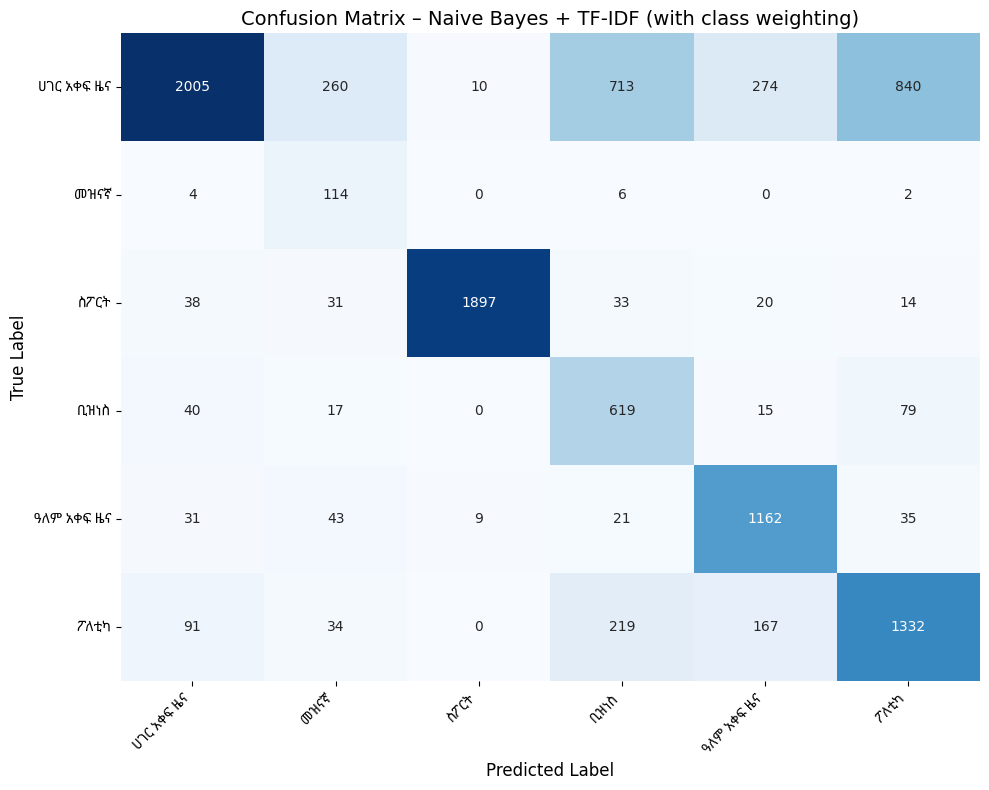


Traditional ML results saved to 'traditional_ml_results.pkl'

MISCLASSIFICATION ANALYSIS
Total misclassified samples: 3046/10175 (29.94%)

Example misclassifications for BUSINESS class (total: 151):

Example 1:
Headline: ከ16 ሚሊየን ብር በላይ ግምት ያለው የኮንትሮባንድ እቃ ተያዘ...
True: Business
Predicted: ሀገር አቀፍ ዜና
--------------------------------------------------

Example 2:
Headline: ከሚላኖ እስከ መቀሌ የዘለቀ ኢንቨስትመንት...
True: Business
Predicted: መዝናኛ
--------------------------------------------------

Example 3:
Headline: በአንድ ቀን 14 ሰርግ ያስተናገደው ሴንትራል ሀዋሳ ሆቴል አሁን ባለ 5 ኮከብ ሆነ...
True: Business
Predicted: መዝናኛ
--------------------------------------------------

Example 4:
Headline: ኢትዮጵያ የለውጥ ጉዞ ፈተናዎችን በአስተውሎት ለመሻገር እና አስተማማኝ ሰላም ለመገንባት ፅኑ አቋም አላት...
True: Business
Predicted: ፖለቲካ
--------------------------------------------------

Example 5:
Headline: ሜጋ ፕሮጀክቶች ችግሮችን በመጋፈጥ በተሻለ ደረጃ እየተፈፀሙ ናቸው -ጠቅላይ ሚኒስትር...
True: Business
Predicted: ፖለቲካ
--------------------------------------------------

Example misclassi

In [ ]:
# ==========================================================
# Traditional ML – Naive Bayes + TF-IDF (with class weighting)
# ==========================================================

# ------------------------------
# Imports
# ------------------------------
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager as fm
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

# ------------------------------
# IMPORTANT: Create combined text column from headline and article
# ------------------------------
# Combine headline and article into a single text field
# You can weight headline more by repeating it or just concatenate
data["text"] = data["headline"] + " " + data["article"]

# Or if you want to give more weight to headlines (optional):
# data["text"] = data["headline"] + " " + data["headline"] + " " + data["article"]

print(f"Combined text column created. Example:")
print(f"Headline: {data['headline'].iloc[0][:100]}...")
print(f"Combined text length: {len(data['text'].iloc[0])} chars")

# ------------------------------
# Use your preprocessed data
# ------------------------------
texts = data["text"].values
labels = data["label"].values  # Already label-encoded
class_names = label_encoder.classes_

print(f"\nTotal samples: {len(texts)}")
print(f"Number of classes: {len(class_names)}")
print(f"Class distribution:\n{data['category'].value_counts()}")

# ------------------------------
# Train/Validation/Test Split (Stratified)
# ------------------------------
X_train, X_temp, y_train, y_temp = train_test_split(
    texts, labels, test_size=0.30, stratify=labels, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=2/3, stratify=y_temp, random_state=42
)

print(f"\nSplit sizes:")
print(f"Train: {len(X_train)} ({100*len(X_train)/len(texts):.1f}%)")
print(f"Val:   {len(X_val)} ({100*len(X_val)/len(texts):.1f}%)")
print(f"Test:  {len(X_test)} ({100*len(X_test)/len(texts):.1f}%)")

# ------------------------------
# TF-IDF Vectorization
# ------------------------------
print("\nVectorizing with TF-IDF...")
tfidf = TfidfVectorizer(
    max_features=30000,   # Limit vocabulary
    ngram_range=(1,2),    # Unigrams + Bigrams
    lowercase=False,      # Keep original Amharic characters
    min_df=2,             # Ignore terms that appear in less than 2 documents
    max_df=0.95,          # Ignore terms that appear in more than 95% of documents
    sublinear_tf=True     # Use 1+log(tf) scaling
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf   = tfidf.transform(X_val)
X_test_tfidf  = tfidf.transform(X_test)

print(f"TF-IDF features: {X_train_tfidf.shape[1]}")
print(f"Training matrix shape: {X_train_tfidf.shape}")

# ------------------------------
# Compute class weights
# ------------------------------
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_prior = class_weights / class_weights.sum()

print(f"\nClass priors (weighted):")
for i, class_name in enumerate(class_names):
    print(f"  {class_name}: {class_prior[i]:.4f}")

# ------------------------------
# Train Naive Bayes
# ------------------------------
print("\nTraining Multinomial Naive Bayes...")
nb_model = MultinomialNB(class_prior=class_prior, alpha=1.0)  # Laplace smoothing
nb_model.fit(X_train_tfidf, y_train)

# ------------------------------
# Validation & Test Evaluation
# ------------------------------
y_val_pred = nb_model.predict(X_val_tfidf)
y_test_pred = nb_model.predict(X_test_tfidf)

print("\n" + "="*60)
print("TRADITIONAL ML RESULTS - Naive Bayes + TF-IDF")
print("="*60)
print(f"✅ Validation Accuracy: {accuracy_score(y_val, y_val_pred):.4f}")
print(f"✅ Test Accuracy: {accuracy_score(y_test, y_test_pred):.4f}")

print("\n" + "="*60)
print("CLASSIFICATION REPORT (Test Set):")
print("="*60)
print(classification_report(
    y_test,
    y_test_pred,
    target_names=class_names,
    zero_division=0
))

# Calculate additional metrics
from sklearn.metrics import f1_score

test_accuracy = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average='macro')
test_weighted_f1 = f1_score(y_test, y_test_pred, average='weighted')

print("\n" + "="*60)
print("SUMMARY METRICS")
print("="*60)
print(f"Accuracy:     {test_accuracy:.4f}")
print(f"Macro F1:     {test_macro_f1:.4f}")
print(f"Weighted F1:  {test_weighted_f1:.4f}")

# Per-class F1 scores
per_class_f1 = f1_score(y_test, y_test_pred, average=None)
print("\n" + "="*60)
print("PER-CLASS F1 SCORES")
print("="*60)
for i, class_name in enumerate(class_names):
    print(f"{class_name:20s}: {per_class_f1[i]:.4f}")

# ------------------------------
# Confusion Matrix – Amharic Labels
# ------------------------------

# Compute confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Install Colab-compatible Ethiopic font
!apt-get install -y fonts-noto -qq

# Try common font paths
font_paths = [
    "/content/NotoSansEthiopic-VariableFont_wdth,wght.ttf",
    "/usr/share/fonts/truetype/noto/NotoSansEthiopic-Regular.ttf",
    "/usr/share/fonts/opentype/noto/NotoSansEthiopic-Regular.otf"
]

font_path = None
for path in font_paths:
    import os
    if os.path.exists(path):
        font_path = path
        break

if font_path:
    font_prop = fm.FontProperties(fname=font_path)
else:
    font_prop = None
    print("Warning: Amharic font not found. Using default font.")

plt.figure(figsize=(10, 8))

# Heatmap
ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    annot_kws={'size': 10}
)

# Set Amharic tick labels
if font_prop:
    ax.set_xticklabels(class_names, rotation=45, ha="right", fontproperties=font_prop, fontsize=10)
    ax.set_yticklabels(class_names, rotation=0, fontproperties=font_prop, fontsize=10)
else:
    ax.set_xticklabels(class_names, rotation=45, ha="right", fontsize=10)
    ax.set_yticklabels(class_names, rotation=0, fontsize=10)

# Labels & title
ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("True Label", fontsize=12)
ax.set_title("Confusion Matrix – Naive Bayes + TF-IDF (with class weighting)", fontsize=14)

plt.tight_layout()
plt.show()

# ------------------------------
# Optional: Save results for comparison
# ------------------------------
traditional_results = {
    'model': 'Naive Bayes + TF-IDF',
    'accuracy': test_accuracy,
    'macro_f1': test_macro_f1,
    'weighted_f1': test_weighted_f1,
    'per_class_f1': per_class_f1,
    'predictions': y_test_pred,
    'true_labels': y_test
}

import pickle
with open('traditional_ml_results.pkl', 'wb') as f:
    pickle.dump(traditional_results, f)

print("\nTraditional ML results saved to 'traditional_ml_results.pkl'")

# ------------------------------
# Misclassification Analysis
# ------------------------------
print("\n" + "="*60)
print("MISCLASSIFICATION ANALYSIS")
print("="*60)

# Find misclassified indices
misclassified_idx = np.where(y_test_pred != y_test)[0]
print(f"Total misclassified samples: {len(misclassified_idx)}/{len(y_test)} ({len(misclassified_idx)/len(y_test)*100:.2f}%)")

# Get original test data indices
test_indices = test_df.index.tolist() if 'test_df' in locals() else range(len(y_test))

# Show examples for BUSINESS class
business_class_name = 'ቢዝነስ'
if business_class_name in class_names:
    business_class_idx = list(class_names).index(business_class_name)
    business_indices = np.where(y_test == business_class_idx)[0]
    business_misclassified = business_indices[y_test_pred[business_indices] != y_test[business_indices]]

    print(f"\nExample misclassifications for BUSINESS class (total: {len(business_misclassified)}):")
    for i, idx in enumerate(business_misclassified[:5]):
        idx_int = int(idx)
        print(f"\nExample {i+1}:")
        if 'test_df' in locals() and idx_int < len(test_df):
            print(f"Headline: {test_df.iloc[idx_int]['headline'][:150]}...")
        else:
            print(f"Text: {X_test[idx_int][:200]}...")
        print(f"True: Business")
        print(f"Predicted: {class_names[y_test_pred[idx_int]]}")
        print("-" * 50)

# Show examples for ENTERTAINMENT class
entertainment_class_name = 'መዝናኛ'
if entertainment_class_name in class_names:
    entertainment_class_idx = list(class_names).index(entertainment_class_name)
    entertainment_indices = np.where(y_test == entertainment_class_idx)[0]
    entertainment_misclassified = entertainment_indices[y_test_pred[entertainment_indices] != y_test[entertainment_indices]]

    print(f"\nExample misclassifications for ENTERTAINMENT class (total: {len(entertainment_misclassified)}):")
    for i, idx in enumerate(entertainment_misclassified[:5]):
        idx_int = int(idx)
        print(f"\nExample {i+1}:")
        if 'test_df' in locals() and idx_int < len(test_df):
            print(f"Headline: {test_df.iloc[idx_int]['headline'][:150]}...")
        else:
            print(f"Text: {X_test[idx_int][:200]}...")
        print(f"True: Entertainment")
        print(f"Predicted: {class_names[y_test_pred[idx_int]]}")
        print("-" * 50)

print("\nTraditional ML training complete!")

✅ Validation Accuracy: 0.8649498722233143
✅ Test Accuracy: 0.8595577395577395

Classification Report (Test Set):

              precision    recall  f1-score   support

  ሀገር አቀፍ ዜና       0.88      0.84      0.86      4102
        መዝናኛ       0.79      0.70      0.74       126
        ስፖርት       0.99      0.99      0.99      2033
        ቢዝነስ       0.65      0.74      0.69       770
  ዓለም አቀፍ ዜና       0.86      0.91      0.88      1301
        ፖለቲካ       0.78      0.79      0.79      1843

    accuracy                           0.86     10175
   macro avg       0.82      0.83      0.82     10175
weighted avg       0.86      0.86      0.86     10175

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-noto is already the newest version (20201225-1build1).
0 upgraded, 0 newly installed, 0 to remove and 45 not upgraded.


/tmp/ipykernel_8928/1404741753.py:109: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Ethiopic.
  plt.tight_layout()
/tmp/ipykernel_8928/1404741753.py:109: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Ethiopic.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Ethiopic.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Ethiopic.
  fig.canvas.print_figure(bytes_io, **kw)


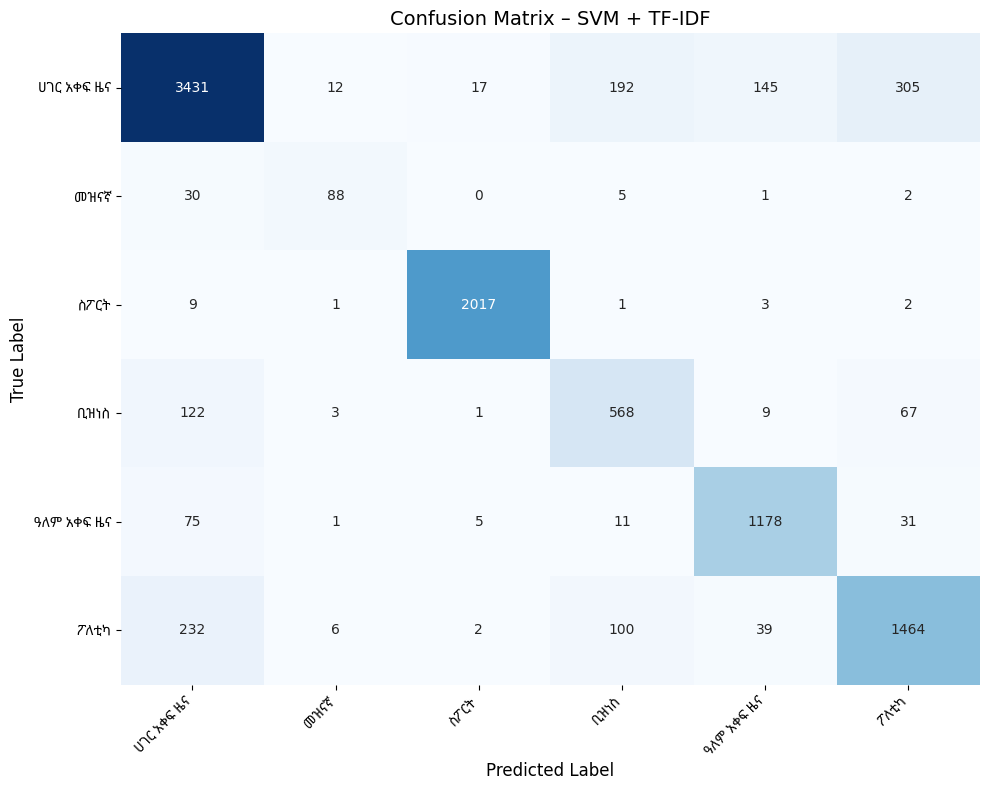

In [ ]:
# ============================================
# Traditional ML – SVM + TF-IDF (with class weighting)
# ============================================

# ------------------------------
# Imports
# ------------------------------
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager as fm

from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ------------------------------
# Use your preprocessed data
# ------------------------------
texts = data["text"].values
labels = data["label"].values  # Already label-encoded
class_names = label_encoder.classes_

# ------------------------------
# Train/Validation/Test Split
# ------------------------------
X_train, X_temp, y_train, y_temp = train_test_split(
    texts, labels, test_size=0.30, stratify=labels, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=2/3, stratify=y_temp, random_state=42
)

# ------------------------------
# TF-IDF Vectorization
# ------------------------------
tfidf = TfidfVectorizer(
    max_features=30000,   # Limit vocabulary
    ngram_range=(1,2),    # Unigrams + Bigrams
    lowercase=False       # Keep original Amharic characters
)
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf   = tfidf.transform(X_val)
X_test_tfidf  = tfidf.transform(X_test)

# ------------------------------
# Train SVM with class weighting
# ------------------------------
svm_model = LinearSVC(
    C=1.0,
    max_iter=5000,
    class_weight='balanced',  # Adjust for minority classes
    random_state=42
)
svm_model.fit(X_train_tfidf, y_train)

# ------------------------------
# Validation & Test Evaluation
# ------------------------------
y_val_pred = svm_model.predict(X_val_tfidf)
y_test_pred = svm_model.predict(X_test_tfidf)

print("✅ Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("✅ Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("\nClassification Report (Test Set):\n")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=class_names,
    zero_division=0
))

# ------------------------------
# Confusion Matrix – Amharic ticks, English labels/title
# ------------------------------

# Compute confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Install Colab-compatible Ethiopic font
!apt-get install -y fonts-noto
font_path = "/usr/share/fonts/truetype/noto/NotoSansEthiopic-Regular.ttf"
font_prop = fm.FontProperties(fname=font_path)

plt.figure(figsize=(10, 8))

# Heatmap
ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False
)

# Set Amharic tick labels
ax.set_xticks(np.arange(len(class_names)) + 0.5)
ax.set_xticklabels(class_names, rotation=45, ha="right", fontproperties=font_prop)
ax.set_yticks(np.arange(len(class_names)) + 0.5)
ax.set_yticklabels(class_names, rotation=0, fontproperties=font_prop)

# Labels & title in English
ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("True Label", fontsize=12)
ax.set_title("Confusion Matrix – SVM + TF-IDF", fontsize=14)

plt.tight_layout()
plt.show()